# Notebook 03 — Traditional Machine Learning

This notebook trains a TF–IDF + Linear SVM classifier on the fully cleaned `hotel_reviews_model_ready.csv`. The vectorizer is fitted on training data only.

In [1]:
from pathlib import Path
import random, json, warnings
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
import matplotlib.pyplot as plt
import seaborn as sns
SEED=42; random.seed(SEED); np.random.seed(SEED)
DATA_PATH=Path('data/processed/hotel_reviews_model_ready.csv')
if not DATA_PATH.exists(): DATA_PATH=Path('/home/ubuntu/work_sentiment/sentiment_analysis_submission/data/processed/hotel_reviews_model_ready.csv')
LABELS=['negative','neutral','positive']
df=pd.read_csv(DATA_PATH,encoding='utf-8-sig',dtype=str,keep_default_na=False)
print('Loaded model-ready data:',df.shape)
MAX_SAMPLES=None
work=df.copy() if MAX_SAMPLES is None else train_test_split(df,train_size=min(MAX_SAMPLES,len(df)),stratify=df['sentiment'],random_state=SEED)[0]
train,test=train_test_split(work,test_size=.2,stratify=work['sentiment'],random_state=SEED)
print(len(train),len(test))

Loaded model-ready data: (397993, 35)


318394 79599


In [2]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
model=Pipeline([('tfidf',TfidfVectorizer(ngram_range=(1,2),min_df=2,max_df=.98,sublinear_tf=True,max_features=150000)),('clf',LinearSVC(C=1.5,class_weight='balanced'))])
model.fit(train['review_clean'],train['sentiment'])
pred=model.predict(test['review_clean'])
print(classification_report(test['sentiment'],pred,labels=LABELS,digits=4,zero_division=0))
metrics={'model':'TF-IDF + Linear SVM','accuracy':accuracy_score(test['sentiment'],pred),'macro_f1':f1_score(test['sentiment'],pred,labels=LABELS,average='macro'),'weighted_f1':f1_score(test['sentiment'],pred,labels=LABELS,average='weighted')}
Path('artifacts').mkdir(exist_ok=True); Path('artifacts/traditional_metrics.json').write_text(json.dumps(metrics,indent=2))

              precision    recall  f1-score   support

    negative     0.7518    0.7616    0.7567     10401
     neutral     0.7034    0.6684    0.6854     15855
    positive     0.9207    0.9319    0.9263     53343

    accuracy                         0.8572     79599
   macro avg     0.7919    0.7873    0.7894     79599
weighted avg     0.8553    0.8572    0.8561     79599



141

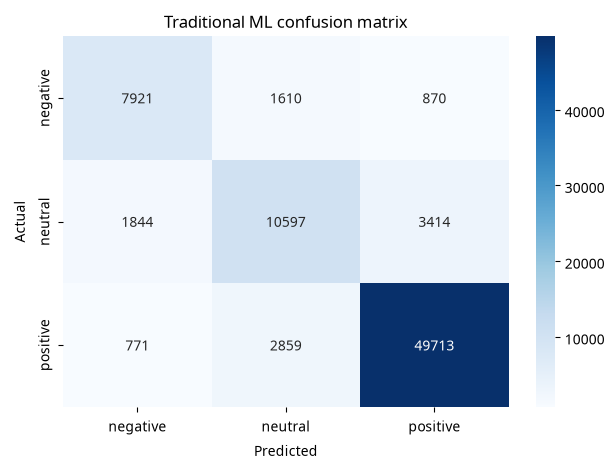

In [3]:
cm=confusion_matrix(test['sentiment'],pred,labels=LABELS)
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=LABELS,yticklabels=LABELS); plt.title('Traditional ML confusion matrix'); plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.tight_layout(); plt.show()

## Interpretation

Report Macro-F1 in addition to Accuracy because the positive class is much larger than the negative class. Save the metrics JSON for the final comparison notebook.